In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [3]:
np.log2(500)

8.965784284662087

## Params

In [22]:
# V_max = 10
# V_width_array = np.arange(V_max).astype(int) + 1
# V_width_array = np.array([1, 5, 10, 15, 20])
# N_iterations_array = np.array([1, 2, 4, 8])
V_width_array = np.array([1, 10])
N_iterations_array = np.array([1, 2, 4, 8])
V_E_buffer = 0
E_width = 1

N_training_repeats = 3
cg_params = {
    "order": 1,
}
# meta_neurons_per_time_bin = 15
N_meta_neurons = 20

critic_params = {
    "hidden_dim": 32,
    "embed_dim": 100,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True}
# opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

# Put variable names here for parameters we want saved.
save_vars = {
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "opt_params",
    "V_width_array",
    "V_E_buffer",
    "E_width",
    "train_fraction",
    "samp_keep",
}

In [23]:
def expt(mov_ind):
    data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
    D = ds.DataNatScenes(data_path, mov_ind=mov_ind)
    print(f'current stimulus is {D.movname}')
    mov_ind = D.mov_ind
    local_save_vars.add('mov_ind')

    experiment_dims = (len(V_width_array), len(N_iterations_array), N_training_repeats)
    mi_averages_test = np.zeros(experiment_dims)
    mi_averages_train = np.zeros(experiment_dims)
    mi_stdevs_train = np.zeros(experiment_dims)
    mi_stdevs_test = np.zeros(experiment_dims)

    coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
    critic_function_array = np.zeros(experiment_dims, dtype=object)
    train_points = np.zeros(experiment_dims, dtype=object)
    test_points = np.zeros(experiment_dims, dtype=object)
    # save_vars.update(
    #     {
    #         "mi_averages_train",
    #         "mi_averages_test",
    #         "mi_stdevs_train",
    #         "mi_stdevs_test",
    #         "train_points",
    #         "test_points",
    #     }
    # )

    for i, V_width in tqdm(enumerate(V_width_array)):
        for j, iterations in enumerate(N_iterations_array):
            for training_repeat in range(N_training_repeats):
                cur_inds = (i, j, training_repeat)
                critic_function = mds.SeparableCritic(**critic_params)
                # N_meta_neurons = V_width * meta_neurons_per_time_bin
                coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, **cg_params)

                # Domains, training and test subsets
                D.reset()
                D.trim(20)
                V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
                current_train_points, current_test_points = tools.generate_train_test_indices(
                    V.P, train_fraction
                )
                V.subset_points(current_train_points)
                E.subset_points(current_train_points)
                train_points[cur_inds] = current_train_points
                test_points[cur_inds] = current_test_points

                # Train current
                opt_params["iterations"] = iterations
                als.IB(
                    X=V.X,
                    Y=E.X,
                    coarse_grainer=coarse_grainer,
                    critic_function=critic_function,
                    **opt_params
                )

                # Measure InfoNCE for train
                T_train = coarse_grainer(V.X.T).numpy().T
                mi_train = als.MI_NCE(
                    X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
                )
                mi_averages_train[cur_inds] = mi_train["mi"]
                mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

                # Measure InfoNCE for test
                V.reset()
                E.reset()
                V.subset_points(current_test_points)
                E.subset_points(current_test_points)

                T_test = coarse_grainer(V.X.T).numpy().T
                mi_test = als.MI_NCE(
                    X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
                )
                mi_averages_test[cur_inds] = mi_test["mi"]
                mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

                critic_function_array[cur_inds] = critic_function
            
    return Namespace(**locals())


In [24]:
data_list = []
local_save_vars = {
    "mov_ind",
    "mi_averages_train",
    "mi_averages_test",
    "mi_stdevs_train",
    "mi_stdevs_test",
    "train_points",
    "test_points",}

for n in range(5):
    cur_data = expt(n)
    cur_save_data = {k: vars(cur_data)[k] for k in local_save_vars}
    data_list.append(cur_save_data)
    

current stimulus is bushes


2it [01:24, 42.25s/it]


current stimulus is water


2it [01:20, 40.09s/it]


current stimulus is leaves


2it [01:23, 41.95s/it]


current stimulus is fish


2it [01:24, 42.43s/it]


current stimulus is opticflow


2it [01:22, 41.26s/it]


## Save

In [25]:
# select variables
save_vars.update({"data_list"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}

In [26]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
full_file_path = os.path.join(save_directory, 'all stim estimates.dat')
print(full_file_path)

/Users/adamkline/Projects/archive/metaneurons/analyses/Markovianity/saved/all stim estimates.dat


In [27]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
    pickle.dump(output_data, f)
tools.record_parameters(full_file_path, output_data)

## Reload

In [28]:
load_path = project_folder + '/analyses/Markovianity/saved/all stim estimates.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

## Skip saving and reloading

In [15]:
save_vars.update({"data_list"})
local_dict = locals()
output_data = {k: local_dict[k] for k in save_vars}
data = Namespace(**output_data)

## Plot

In [40]:
mi_test = np.array([a["mi_averages_test"] for a in data.data_list]).mean(axis=-1)
mi_train = np.array([a["mi_averages_train"] for a in data.data_list]).mean(axis=-1)

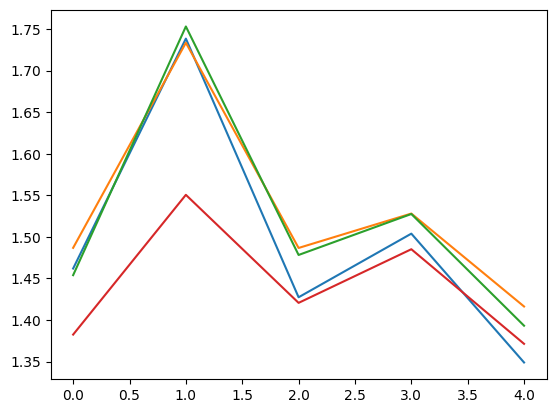

In [45]:
plt.plot(mi_test[:,1,:] / mi_test[:,0,:])

In [54]:
mi_test[:,1,2] / mi_test[:,0,2]

array([1.45394003, 1.75308302, 1.47823753, 1.52753212, 1.39314853])

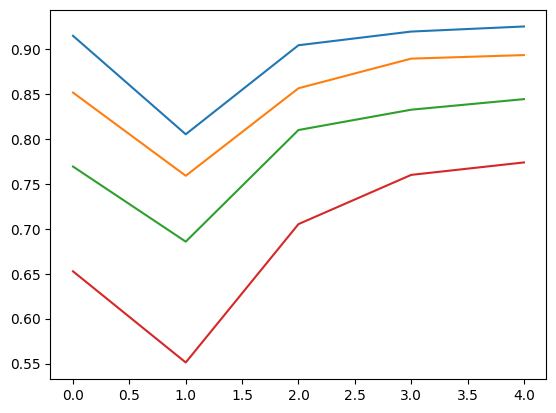

In [46]:
plt.plot(mi_test[:,1,:] / mi_train[:,1,:])

In [16]:
def process_expt(ns):
    average_test = np.average(ns.mi_averages_test, axis=-1)
    average_train = np.average(ns.mi_averages_train, axis=-1)
    return average_train, average_test

In [ ]:
average_test = []
average_train = []
for n in range(2):
    a, b = process_expt(data.data_list[n])
    average_train.append(a)
    average_test.append(b)

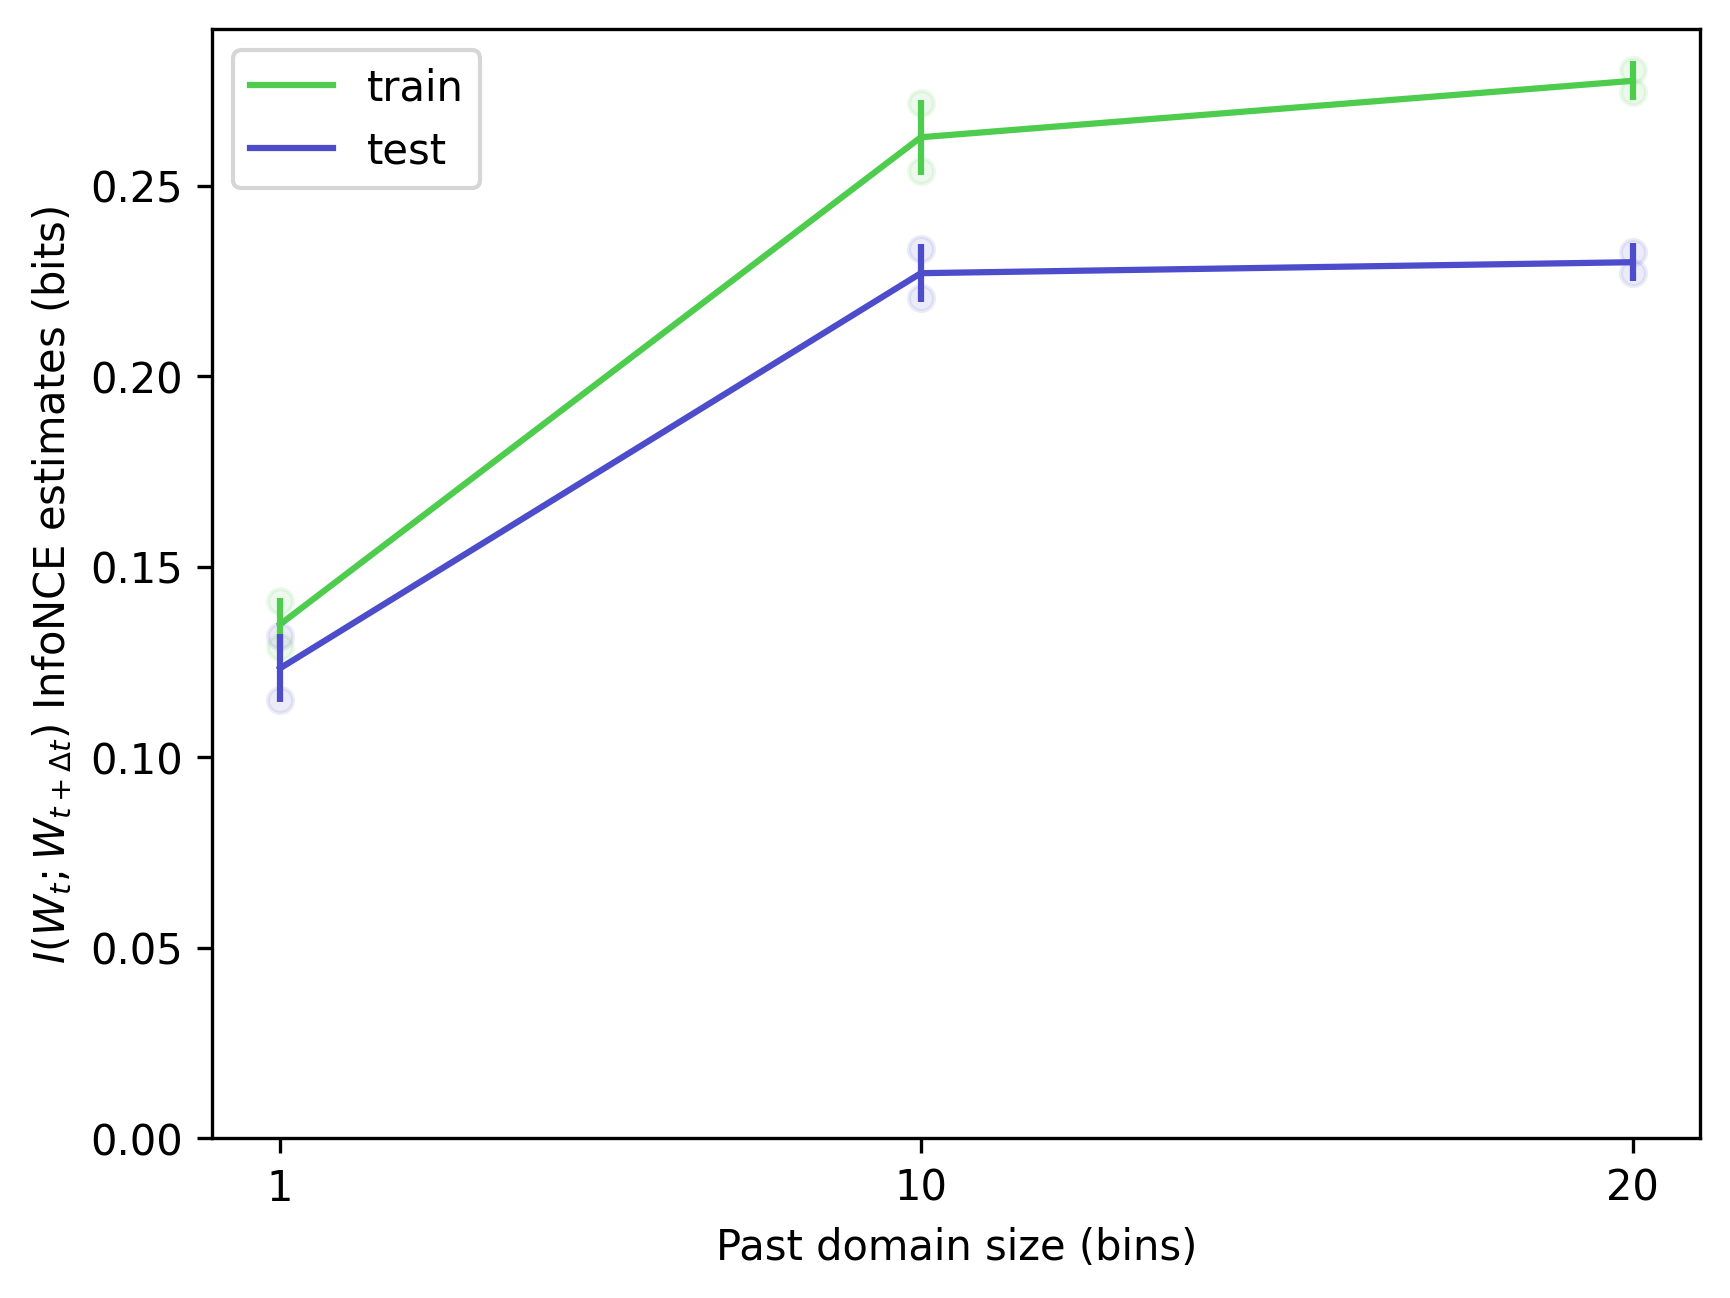

In [8]:
x = data.V_width_array

c1 = 0.3
c2 = 0.8
alp = 0.1
plt.figure(dpi=300)
plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='train')
plt.plot(x, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='test');
plt.plot(x, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))
plt.ylim(ymin=0)
ax = plt.gca()
ax.set_xticks(x)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('Past domain size (bins)')
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();

In [9]:
data.mi_averages_test / np.log(2)

array([[0.11490664, 0.13175715],
       [0.23343995, 0.2206005 ],
       [0.22718953, 0.23261312]])

In [10]:
np.max(data.mi_averages_test) / data.mi_averages_test[0]

array([2.0315618 , 1.77174408])

In [ ]:
np.max(data.mi_averages_test) / data.mi_averages_test[0]

array([1.71657126, 1.74546079])

In [ ]:
x = data.V_width_array
y_train = (average_train[-1] - average_train)/np.log(2)
t_halfmax_train = tools.arg_half_max(y_train)
y_test = (average_test[-1] - average_test)/np.log(2)
t_halfmax_test = tools.arg_half_max(y_test)
tau_train = t_halfmax_train / np.log(2)
tau_test = t_halfmax_test / np.log(2)
y_train_theory = np.exp( - (x - 1) / tau_train) * y_train[0]
y_test_theory = np.exp(- (x - 1) / tau_test) * y_test[0]

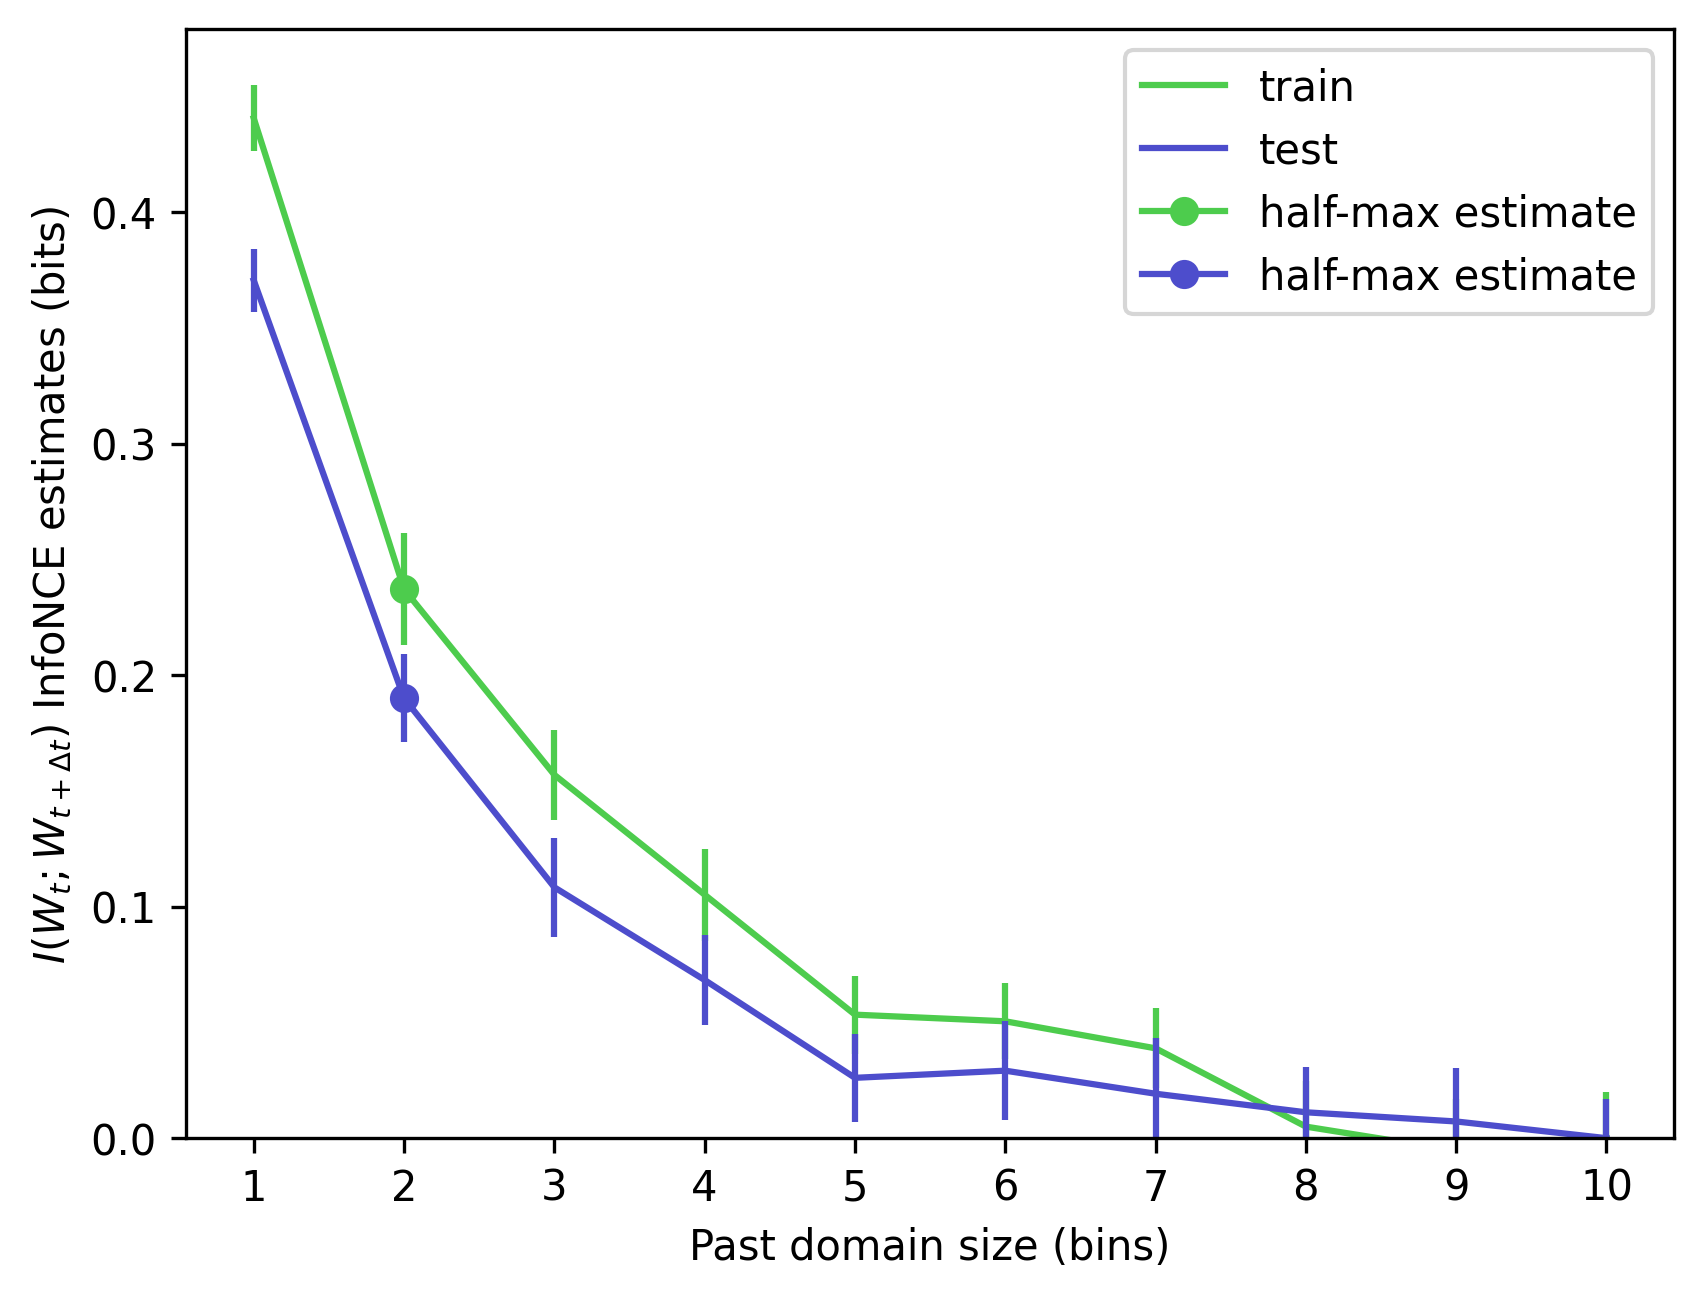

In [ ]:
c1 = 0.3
c2 = 0.8
alp = 0.1
plt.figure(dpi=300)
plt.plot(x, y_train, color=(c1,c2,c1), label='train')
plt.plot(x, y_test, color=(c1,c1,c2), label='test');

# plt.plot(x, y_train_theory, 'k')
# plt.plot(x, y_test_theory, 'k')

plt.plot(x[t_halfmax_train], y_train[t_halfmax_train], color=(c1,c2,c1), marker='o', label='half-max estimate')
plt.plot(x[t_halfmax_test], y_test[t_halfmax_test], color=(c1,c1,c2), marker='o', label='half-max estimate');

plt.errorbar(x, y_train, yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, y_test, yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))

plt.ylim(ymin=0)
ax = plt.gca()
ax.set_xticks(x)
# plt.title('Predictive info quickly saturates at a few meta-neurons')
plt.xlabel('Past domain size (bins)')
plt.ylabel(r'$I(W_{t};W_{t+\Delta t})$ InfoNCE estimates (bits)')
plt.legend();